# Importando Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importando os Datasets do Site

In [2]:
import urllib.request
import zipfile
import io

# 1. URL do arquivo ZIP na UCI
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# 2. Baixar o ZIP em memória
req = urllib.request.urlopen(url)
zip_bytes = io.BytesIO(req.read())

# 3. Abrir o ZIP e inspecionar/extrair os arquivos
with zipfile.ZipFile(zip_bytes, 'r') as z:
    print("Arquivos encontrados no ZIP:", z.namelist())

    # Caso os CSVs estejam dentro de um sub-zip
    if 'student.zip' in z.namelist():
        sub_zip_bytes = io.BytesIO(z.read('student.zip'))
        with zipfile.ZipFile(sub_zip_bytes, 'r') as sub_z:
            print("Arquivos no student.zip:", sub_z.namelist())
            df_mat = pd.read_csv(sub_z.open('student-mat.csv'), sep=';')
            df_por = pd.read_csv(sub_z.open('student-por.csv'), sep=';')
    else:
        df_mat = pd.read_csv(z.open('student-mat.csv'), sep=';')
        df_por = pd.read_csv(z.open('student-por.csv'), sep=';')

print(f"\nMatemática carregado: {df_mat.shape}")
print(f"Português carregado: {df_por.shape}")

Arquivos encontrados no ZIP: ['.student.zip_old', 'student.zip']
Arquivos no student.zip: ['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']

Matemática carregado: (395, 33)
Português carregado: (649, 33)


# Tratamento dos Dados

Os dados vem com muitas informações que não serão necessárias. É essencial fazer uma limpeza neles antes de prosseguir com as análises e a criação do modelo.

### Juntando os Datasets

In [3]:
df_bruto = pd.concat([df_mat, df_por], ignore_index=True)

# Criando a cópia que sofrerá alterações
df = df_bruto.copy()

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      1044 non-null   object
 1   sex         1044 non-null   object
 2   age         1044 non-null   int64 
 3   address     1044 non-null   object
 4   famsize     1044 non-null   object
 5   Pstatus     1044 non-null   object
 6   Medu        1044 non-null   int64 
 7   Fedu        1044 non-null   int64 
 8   Mjob        1044 non-null   object
 9   Fjob        1044 non-null   object
 10  reason      1044 non-null   object
 11  guardian    1044 non-null   object
 12  traveltime  1044 non-null   int64 
 13  studytime   1044 non-null   int64 
 14  failures    1044 non-null   int64 
 15  schoolsup   1044 non-null   object
 16  famsup      1044 non-null   object
 17  paid        1044 non-null   object
 18  activities  1044 non-null   object
 19  nursery     1044 non-null   object
 20  higher  

### Verificando a Existência de Duplicatas e Nulos

In [5]:
print(f'Quantidade de registros duplicados: {df.duplicated().sum()}')
print(f'Quantidade de registros nulos: {df.isna().sum().sum()}')

Quantidade de registros duplicados: 0
Quantidade de registros nulos: 0


### Removendo Colunas Desnecessárias

In [6]:
df = df.drop(columns=[
    'school',
    'sex',
    'address',
    'famsize',
    'Pstatus',
    'Medu',
    'Fedu',
    'Mjob',
    'Fjob',
    'reason',
    'guardian',
    'traveltime',
    'studytime',
    'schoolsup',
    'famsup',
    'paid',
    'activities',
    'nursery',
    'higher',
    'internet',
    'romantic',
    'famrel',
    'freetime',
    'goout',
    'Dalc',
    'Walc',
    'health'
])

### Renomeando Colunas para a Nomenclatura do Sistema

In [7]:
df = df.rename(columns={
    'age': 'idade',
    'failures': 'historico_reprovacao',
    'absences': 'ausencias',
    'G1': 'nota_t1',
    'G2': 'nota_t2',
    'G3': 'nota_t3',
})

### Criando um ID para cada Aluno

In [8]:
df['id_aluno'] = [f'ALU_{i + 1:04d}' for i in range(len(df))]

### Adaptando as Notas e Ausências

In [9]:
df['nota_t1'] = (df['nota_t1'] / 2).round(1)
df['nota_t2'] = (df['nota_t2'] / 2).round(1)
df['nota_t3'] = (df['nota_t3'] / 2).round(1)

df['media_geral'] = ((df['nota_t1'] + df['nota_t2'] + df['nota_t3']) / 3).round(1)

df['frequencia_percentual'] = (((200 - df['ausencias']) / 200) * 100).clip(0, 100).round(1)

### Reordenando as Colunas

In [10]:
df = df[[
    'id_aluno',
    'idade',
    'historico_reprovacao',
    'ausencias',
    'frequencia_percentual',
    'nota_t1',
    'nota_t2',
    'nota_t3',
    'media_geral'
]]

In [11]:
df.sort_values(by='nota_t3').head()

,id_aluno,idade,historico_reprovacao,ausencias,frequencia_percentual,nota_t1,nota_t2,nota_t3,media_geral
1021,ALU_1022,18,0,0,100.0,3.5,2.5,0.0,2.0
914,ALU_0915,16,0,0,100.0,4.0,3.5,0.0,2.5
835,ALU_0836,16,0,0,100.0,3.5,0.0,0.0,1.2
131,ALU_0132,15,0,0,100.0,4.0,0.0,0.0,1.3
135,ALU_0136,15,0,0,100.0,5.5,0.0,0.0,1.8


## Dividindo os registros em 3 categorias: Aprovado, Reprovado e Evadido

A condição para o aluno ser reprovado é sua média geral ser menor que 5.0.

Já a condição para considerar seu status como evadido é ele ter ido a menos do que 75% das aulas do ano. Porém, se o aluno tiver desistido da disciplina, o sistema da escola para de computar suas faltas, podendo manter sua frequência como 100% mesmo que não tenha feito as provas. Por isso, achei uma boa ideia adicionar um OU na condição para que se ele não tiver feito a prova final, ele também seja considerado como evadido.

In [12]:
condicoes = [
    (df['frequencia_percentual'] < 75.0) | (df['nota_t3'] == 0.0),
    (df['media_geral'] < 5.0)
]
escolhas = ['Evadido', 'Reprovado']

df['situacao_final'] = np.select(condicoes, escolhas, default='Aprovado')

df['situacao_final'].value_counts()

,count
situacao_final,
Aprovado,722
Reprovado,266
Evadido,56


# Análise Exploratória

Depois do tratamento e limpeza dos dados, chega o momento de analisar esses dados.

### Impacto do Histórico de Reprovação

Com o gráfico abaixo, é possível perceber que quanto mais reprovações um estudante tenha, maiores são as chances dele reprovar de novo, ou pior, sair da escola.

**O que fazer a respeito?** A escola não precisa nem esperar a primeira prova do ano. Qualquer estudante que já tenha reprovado antes deve entrar no grupo de atenção para acompanhamento pedagógico.

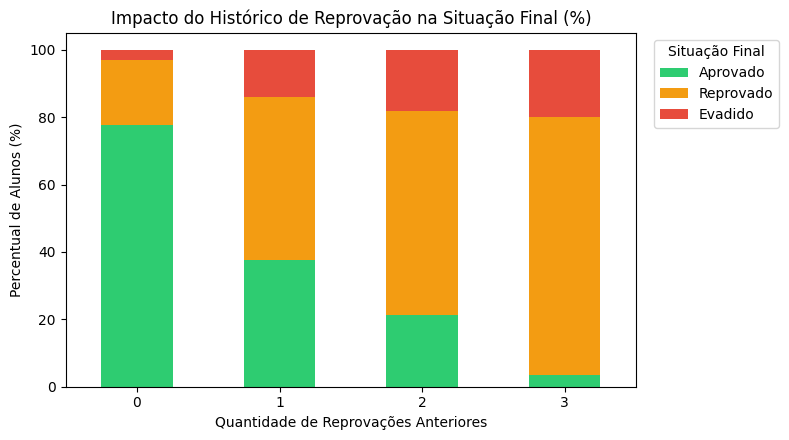

In [13]:
tab_hist = pd.crosstab(df['historico_reprovacao'], df['situacao_final'], normalize='index') * 100

tab_hist[['Aprovado', 'Reprovado', 'Evadido']].plot(kind='bar', stacked=True, figsize=(8, 4.5), color=['#2ecc71', '#f39c12', '#e74c3c'], rot=0)

plt.title('Impacto do Histórico de Reprovação na Situação Final (%)')
plt.xlabel('Quantidade de Reprovações Anteriores')
plt.ylabel('Percentual de Alunos (%)')
plt.legend(title='Situação Final', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Composição dos Casos de Evasão

Com o gráfico abaixo, fica óbvio que a maioria dos estudantes que saem da escola tem zero faltas. O motivo disso acontecer é porque a escola para de computar as faltas depois do estudante sair.

Apenas 3 estudantes perderam por excesso de faltas. Então, se a escola usar isso como seu único parâmetro para identificar possíveis evasões, ela irá deixar de notar muitos evasores.

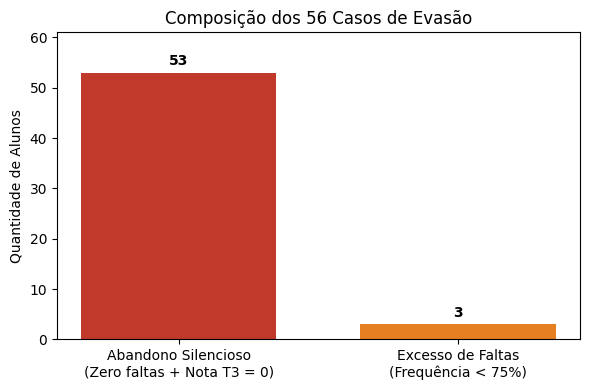

In [14]:
evadidos = df[df['situacao_final'] == 'Evadido']
por_falta = (evadidos['frequencia_percentual'] < 75.0).sum()
abandono = len(evadidos) - por_falta

plt.figure(figsize=(6, 4))
barras = plt.bar(['Abandono Silencioso\n(Zero faltas + Nota T3 = 0)', 'Excesso de Faltas\n(Frequência < 75%)'],
                 [abandono, por_falta], color=['#c0392b', '#e67e22'], width=0.7)

plt.bar_label(barras, padding=3, fontweight='bold')
plt.title(f'Composição dos {len(evadidos)} Casos de Evasão')
plt.ylabel('Quantidade de Alunos')
plt.ylim(0, max(abandono, por_falta) + 8)
plt.tight_layout()
plt.show()

### Situação Final por Nota no 1° Trimestre

Observando o gráfico abaixo, é evidente que a nota que o aluno recebe no primeiro trimestre tem grande influência na situação final dele.

Estudantes com nota crítica tem 0% de taxa de aprovação, com cerca de 25% deles acabando como evadidos. A escola deve prestar muita atenção nessa primeira nota e acompanhar os alunos com notas baixas.



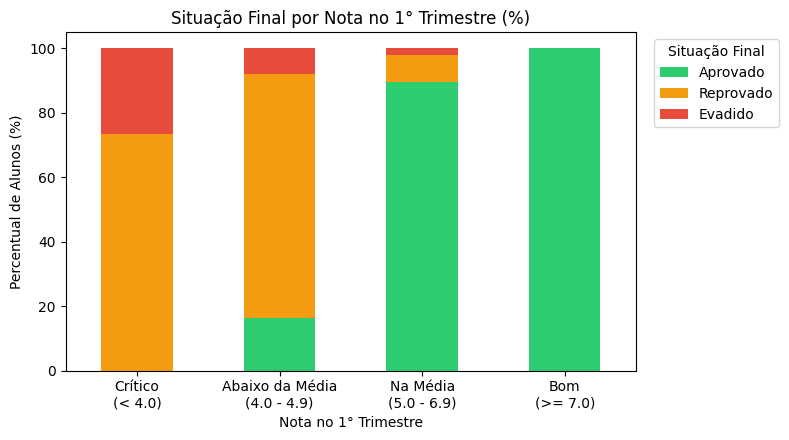

In [15]:
faixas = pd.cut(df['nota_t1'], bins=[-0.1, 3.9, 4.9, 6.9, 10], labels=['Crítico\n(< 4.0)', 'Abaixo da Média\n(4.0 - 4.9)', 'Na Média\n(5.0 - 6.9)', 'Bom\n(>= 7.0)'])

tab_t1 = pd.crosstab(faixas, df['situacao_final'], normalize='index') * 100
tab_t1[['Aprovado', 'Reprovado', 'Evadido']].plot(kind='bar', stacked=True, figsize=(8, 4.5), color=['#2ecc71', '#f39c12', '#e74c3c'], rot=0)

plt.title('Situação Final por Nota no 1° Trimestre (%)')
plt.xlabel('Nota no 1° Trimestre')
plt.ylabel('Percentual de Alunos (%)')
plt.legend(title='Situação Final', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Conclusão da Análise Exploratória

Após as análises e gráficos, foram definidos 3 pilares de atenção prioritária:

*   **Triagem no dia 1:** Alunos com 1 ou mais reprovações anteriores já entram com risco alto. É recomendado acompanhá-los desde o início do ano.

*   **A lista de presença engana:** Aproximadamente 95% dos evadidos não passam do limite de faltas. Monitorar só a presença deixa quase todos eles passarem.

*   **A nota inicial é um indicativo:** A coordenação não precisa esperar o fim do ano para agir. Qualquer nota abaixo de 5.0 no 1° Trimestre já merece atenção.
